## Setup: install libraries (run once)

In [1]:
# Uncomment the next line the first time if a library is missing
# !pip install pandas scikit-learn torch matplotlib

## Task 1: Load the dataset and preprocess it for training
Steps: import libraries → load the CSV with `pd.read_csv` → split into features `X` and target `y` → `train_test_split` (80/20) → standardize with `StandardScaler` → convert to PyTorch tensors.

In [2]:
import os
import pandas as pd
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Fixed seeds so the results are the same every time you run the notebook
torch.manual_seed(42)
np.random.seed(42)

URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/rk7VDaPjMp1h5VXS-cUyMg/league-of-legends-data-large.csv"
LOCAL = "league_of_legends_data_large.csv"

# Use the local copy if it exists, otherwise download it from IBM's server
data = pd.read_csv(LOCAL if os.path.exists(LOCAL) else URL)
print("Shape:", data.shape)
data.head()

Shape: (1000, 9)


,win,kills,deaths,assists,gold_earned,cs,wards_placed,wards_killed,damage_dealt
0,0,16,6,19,17088,231,11,7,15367
1,1,8,8,5,14865,259,10,2,38332
2,0,0,17,11,15919,169,14,5,24642
3,0,19,11,1,11534,264,14,3,15789
4,0,12,7,6,18926,124,15,7,40268


In [3]:
# Features (X) = every column except 'win'; target (y) = 'win'
X = data.drop('win', axis=1)
y = data['win']

# 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize: mean 0, standard deviation 1 (fit ONLY on training data)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convert to PyTorch tensors; y gets shape (n, 1) to match the model output
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)
y_test = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

X_train: torch.Size([800, 8]) | X_test: torch.Size([200, 8])
y_train: torch.Size([800, 1]) | y_test: torch.Size([200, 1])


## Task 2: Implement a logistic regression model using PyTorch
One linear layer followed by a sigmoid: $\hat{y} = \sigma(Wx + b)$. Loss: `nn.BCELoss` (binary cross-entropy). Optimizer: `optim.SGD` with learning rate 0.01.

In [4]:
import torch.nn as nn
import torch.optim as optim

class LogisticRegressionModel(nn.Module):
    def __init__(self, input_dim):
        super(LogisticRegressionModel, self).__init__()
        self.linear = nn.Linear(input_dim, 1)   # one output = probability of a win

    def forward(self, x):
        return torch.sigmoid(self.linear(x))     # squash to a value between 0 and 1

input_dim = X_train.shape[1]
model = LogisticRegressionModel(input_dim)
criterion = nn.BCELoss()
optimizer = optim.SGD(model.parameters(), lr=0.01)
print(model)

LogisticRegressionModel(
  (linear): Linear(in_features=8, out_features=1, bias=True)
)


## Task 3: Train the logistic regression model
For each epoch: `zero_grad()` → forward pass → compute loss → `backward()` → `step()`. Then evaluate accuracy on train and test sets with threshold 0.5.

In [5]:
def accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        preds = (model(X) >= 0.5).float()
        return (preds == y).float().mean().item()

def train(model, optimizer, epochs=1000, print_every=100):
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()              # 1. clear old gradients
        outputs = model(X_train)           # 2. forward pass (predictions)
        loss = criterion(outputs, y_train) # 3. loss
        loss.backward()                    # 4. backpropagation
        optimizer.step()                   # 5. update weights
        if print_every and (epoch + 1) % print_every == 0:
            print(f"Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}")
    return model

train(model, optimizer, epochs=1000)

train_acc = accuracy(model, X_train, y_train)
test_acc = accuracy(model, X_test, y_test)
print(f"\nTraining Accuracy: {train_acc*100:.2f}%")
print(f"Testing Accuracy:  {test_acc*100:.2f}%")

Epoch [100/1000], Loss: 0.7081
Epoch [200/1000], Loss: 0.6993
Epoch [300/1000], Loss: 0.6939
Epoch [400/1000], Loss: 0.6905
Epoch [500/1000], Loss: 0.6884
Epoch [600/1000], Loss: 0.6871
Epoch [700/1000], Loss: 0.6864
Epoch [800/1000], Loss: 0.6859
Epoch [900/1000], Loss: 0.6857
Epoch [1000/1000], Loss: 0.6855

Training Accuracy: 53.62%
Testing Accuracy:  49.00%


## Task 4: Optimization with L2 regularization
`weight_decay=0.01` adds an L2 penalty on the weights, which keeps them small and reduces **overfitting**. We retrain a fresh model with the same loop.

In [6]:
torch.manual_seed(42)
model_l2 = LogisticRegressionModel(input_dim)
optimizer_l2 = optim.SGD(model_l2.parameters(), lr=0.01, weight_decay=0.01)

train(model_l2, optimizer_l2, epochs=1000)

train_acc_l2 = accuracy(model_l2, X_train, y_train)
test_acc_l2 = accuracy(model_l2, X_test, y_test)
print(f"\nTraining Accuracy (L2): {train_acc_l2*100:.2f}%")
print(f"Testing Accuracy (L2):  {test_acc_l2*100:.2f}%")

Epoch [100/1000], Loss: 0.7075
Epoch [200/1000], Loss: 0.6987
Epoch [300/1000], Loss: 0.6932
Epoch [400/1000], Loss: 0.6900
Epoch [500/1000], Loss: 0.6880
Epoch [600/1000], Loss: 0.6869
Epoch [700/1000], Loss: 0.6862
Epoch [800/1000], Loss: 0.6858
Epoch [900/1000], Loss: 0.6856
Epoch [1000/1000], Loss: 0.6854

Training Accuracy (L2): 53.50%
Testing Accuracy (L2):  49.50%


## Task 5: Visualize performance and interpret the results
Confusion matrix, classification report, ROC curve and AUC on the **test set** (using the L2 model).

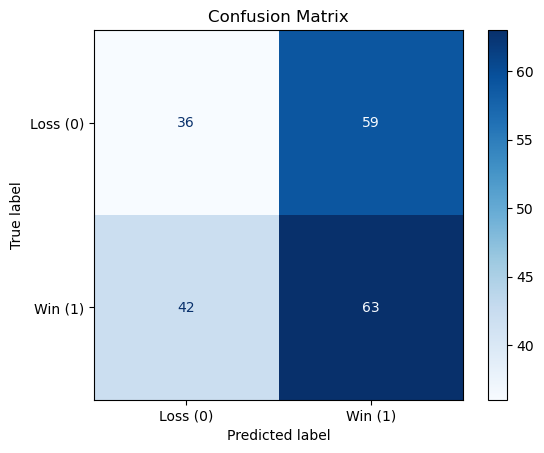

Classification Report:

              precision    recall  f1-score   support

        Loss       0.46      0.38      0.42        95
         Win       0.52      0.60      0.56       105

    accuracy                           0.49       200
   macro avg       0.49      0.49      0.49       200
weighted avg       0.49      0.49      0.49       200



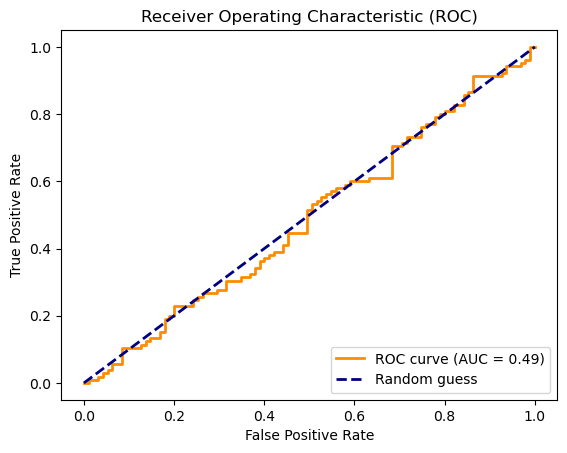

AUC: 0.4906


In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc, ConfusionMatrixDisplay

model_l2.eval()
with torch.no_grad():
    y_prob = model_l2(X_test).numpy().ravel()   # probabilities
y_pred = (y_prob >= 0.5).astype(int)            # class labels
y_true = y_test.numpy().ravel().astype(int)

# 1) Confusion matrix
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['Loss (0)', 'Win (1)']).plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

# 2) Classification report
print("Classification Report:\n")
print(classification_report(y_true, y_pred, target_names=['Loss', 'Win']))

# 3) ROC curve + AUC
fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc='lower right')
plt.show()
print(f"AUC: {roc_auc:.4f}")

**Interpretation of my results:**
- **Confusion matrix:** the model correctly predicted 36 losses and 63 wins (99 of 200 correct). It made 59 false "win" predictions and 42 false "loss" predictions, so it tends to predict "Win" too often.
- **Classification report:** overall accuracy is 49%. The model is slightly better at finding wins (recall 0.60, F1 0.56) than losses (recall 0.38, F1 0.42).
- **ROC / AUC:** AUC = 0.49, and the orange curve almost follows the diagonal "random guess" line. The model is no better than random guessing on this data.
- **L2 regularization** changed the test accuracy only slightly (49.0% → 49.5%), because the model is too simple to overfit here.
- **Conclusion:** these 8 end-of-game statistics do not separate wins from losses in a linear way. A better model would need more informative features or a non-linear model.

## Task 6: Save and load the trained model

In [8]:
# Save only the learned weights (state dictionary)
torch.save(model_l2.state_dict(), 'lol_logistic_model.pth')
print("Model saved to lol_logistic_model.pth")

# Load them into a brand-new model instance
loaded_model = LogisticRegressionModel(input_dim)
loaded_model.load_state_dict(torch.load('lol_logistic_model.pth'))
loaded_model.eval()   # evaluation mode

loaded_test_acc = accuracy(loaded_model, X_test, y_test)
print(f"Loaded model test accuracy: {loaded_test_acc*100:.2f}%")
print("Same as before saving?", abs(loaded_test_acc - test_acc_l2) < 1e-6)

Model saved to lol_logistic_model.pth
Loaded model test accuracy: 49.50%
Same as before saving? True


## Task 7: Hyperparameter tuning – find the best learning rate
For each learning rate we **reinitialize** the model and optimizer, train 100 epochs, and record test accuracy.

In [9]:
learning_rates = [0.01, 0.05, 0.1]
results = {}

for lr in learning_rates:
    torch.manual_seed(42)
    m = LogisticRegressionModel(input_dim)
    opt = optim.SGD(m.parameters(), lr=lr, weight_decay=0.01)
    train(m, opt, epochs=100, print_every=0)
    results[lr] = accuracy(m, X_test, y_test)
    print(f"Learning rate {lr}: Test Accuracy = {results[lr]*100:.2f}%")

best_lr = max(results, key=results.get)
print(f"\nBest learning rate: {best_lr} with Test Accuracy = {results[best_lr]*100:.2f}%")

Learning rate 0.01: Test Accuracy = 50.00%
Learning rate 0.05: Test Accuracy = 49.50%
Learning rate 0.1: Test Accuracy = 49.50%

Best learning rate: 0.01 with Test Accuracy = 50.00%


## Task 8: Feature importance
In logistic regression each feature has one weight. A larger **absolute** weight means the feature has a bigger effect on the prediction; the sign shows the direction (+ helps winning, − hurts).

     Feature  Importance
 gold_earned    0.178853
       kills    0.133559
wards_placed    0.101899
wards_killed   -0.043339
     assists   -0.018096
      deaths    0.015243
          cs   -0.014044
damage_dealt   -0.000968


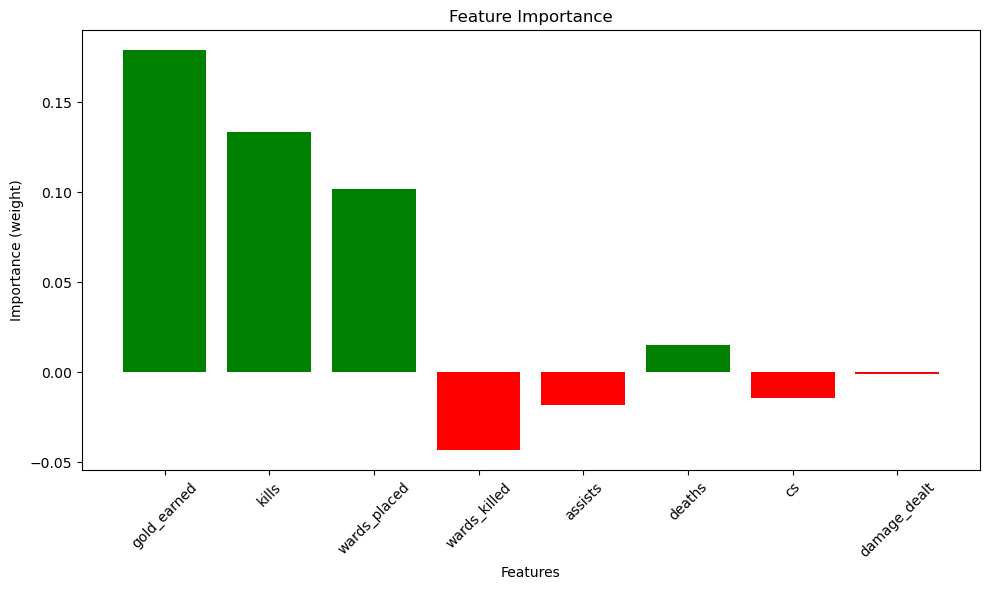


Top 3 most important features: ['gold_earned', 'kills', 'wards_placed']


In [10]:
weights = model_l2.linear.weight.data.numpy().flatten()
feature_names = X.columns

feature_importance = pd.DataFrame({'Feature': feature_names, 'Importance': weights})
feature_importance = feature_importance.sort_values(by='Importance', key=abs, ascending=False)
print(feature_importance.to_string(index=False))

plt.figure(figsize=(10, 6))
plt.bar(feature_importance['Feature'], feature_importance['Importance'],
        color=['green' if w > 0 else 'red' for w in feature_importance['Importance']])
plt.xlabel('Features')
plt.ylabel('Importance (weight)')
plt.title('Feature Importance')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("\nTop 3 most important features:", list(feature_importance['Feature'].head(3)))

## Conclusion
- Built a PyTorch logistic regression model to predict League of Legends match outcomes.
- Compared training with and without L2 regularization, visualized results (confusion matrix, ROC/AUC), saved/loaded the model, tuned the learning rate, and ranked feature importance.
- Logistic regression is a simple linear model; accuracy could be improved with more informative features or a non-linear model (e.g., a small neural network).